### ASTR 8070: Astrostatistics
***N. Pol***
___

# Homework 4
### Due: Wednesday, Oct. 14 11.59pm CST
---

## Problem 1

This problem uses a dataset in `/coursework/homeworks/hw_data/`.

1) Read in `hw4_data_1.npy`. This is a (10 x 2) numpy array, with voltage measurements in the first column and heteroscedastic voltage uncertainties in the second column. Compute the sample mean and the standard error on the sample mean for this data.

2) Fit the appropriate ln-likelihood function and find the best-fit mean voltage.

3) Compute and plot the Bayesian posterior probability density (*not the log posterior*) for the mean voltage assuming a uniform prior for the mean in the range 3 to 7. Make sure this posterior pdf is normalized!

4) By either drawing samples from this posterior, or using your gridded posterior pdf to make a cdf, find the equal-tailed 68.3% credible region for the mean, and compare the upper and lower boundaries to the sample mean plus/minus the standard error, respectively. *Also* find the MAP value of the mean.

5) Repeat (3) and (4) this time with a prior on the mean that is uniform in the range 4.6 to 5.4. 

6) Now, imagine that we read an old paper about the experiment that gave us the voltage measurements, and they found that the mean was actually $6\pm0.3$. Repeat (3) and (4) this time with a Gaussian prior on the mean centered at $6$ with standard deviation of $0.3$.

7) Plot all of the normalized posterior pdfs for $\mu$ from (3), (5), and (6) on the same plot, making sure that the xlim of the plot spans 0 to 10.

8) You have made sure that the posterior pdfs are properly normalized, but until now you have ignored the meaning of that normalization constant. It is the Bayesian evidence for the particular model you have applied! Compute the evidence under a new model where the prior for the mean is a delta function at the best-fit value you found in (1) *(think about this and don't just immediately go looking for a `scipy.stats` delta function)*. Compare this to the evidence found under the prior in (3). Taking ratios to make a Bayes factor, which model is favored? Is there much of an Occam penalty by having the wide prior compared to knowing the mean exactly? 

### Solution

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy.integrate import trapezoid

--Pt. 1--
Sample Mean: 5.1060
Sample Mean Error: 0.3284

-- Pt. 2 --
Best-fit Mean Voltage: 4.9421

-- Pt. 3 & 4 --
Map Value: 4.9425
68.3% Credible Region: [4.5115, 5.3725]
Sample Mean +/- Stderr bounds: [4.7776, 5.4344]

-- Pt. 5 --
Map Value: 4.9425
68.3% Credible Region: [4.7355, 5.2385]

-- Pt. 6 --
Map Value: 5.6536
68.3% Credible Region: [5.4075, 5.9006]



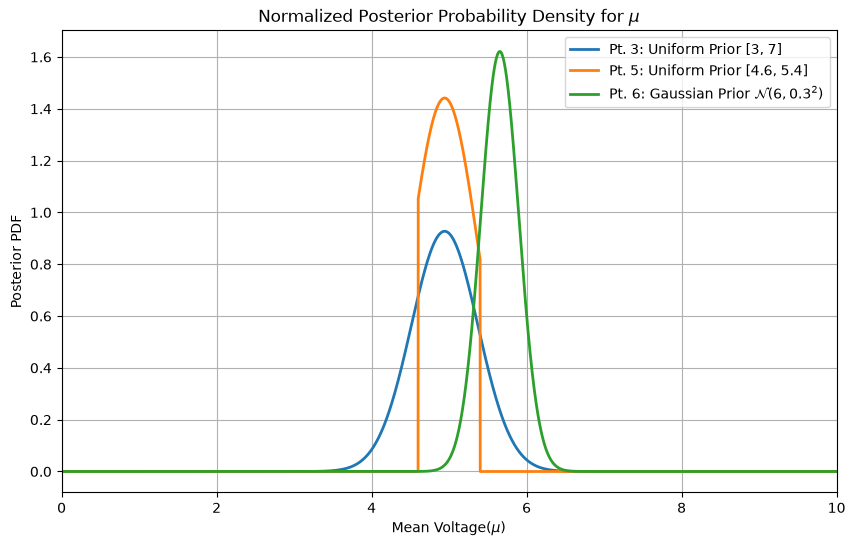

-- Pt. 8--
Evidence for Uniform Prior Model: 2.8919e-08
Evidence for Delta Function Model: 9.9754e-08
Bayes Factor (Delta / Uniform): 3.45
The Delta Function Model is favored.

Occam Penalty Context:
The wide prior splits its probability accross an interval of 4 units
Because the data restricts parameter options to a narrow range, the empty volume
of the unconstrained uniform prior operates directly as an Occam Penalty paramenter.


In [16]:
### Part 1 ###
data = np.load('C:/Users/aaron/Git/repos/astrostats_ttu_fall26/coursework/student_folders/aaron_hawley/homeworks/hw_data/hw4_data_1.npy')
x = data[:, 0]
sigma = data[:, 1]

sample_mean = np.mean(x)
sample_stderr = np.std(x, ddof=1) / np.sqrt(len(x))

print("--Pt. 1--")
print(f"Sample Mean: {sample_mean:.4f}")
print(f"Sample Mean Error: {sample_stderr:.4f}\n")

### Part 2 ###
weight = 1.0 / sigma**2
mu_best = np.sum(x * wight) / np.sum(weight)

print("-- Pt. 2 --")
print(f"Best-fit Mean Voltage: {mu_best:.4f}\n")

### Part 3 ###
mu_grid = np.linspace(0, 10, 10000)
dmu = mu_grid[1] - mu_grid[0]

ln_L = -0.5 * np.sum(np.log(2 * np.pi * sigma[:, None]**2) + ((x[:, None] - mu_grid) / sigma[:, None])**2, axis=0)
L_scaled = np.exp(ln_L - np.max(ln_L))
L_full = np.exp(ln_L)

prior_0 = np.where((mu_grid >= 3) & (mu_grid <= 7), 1.0 / (7 - 3), 0.0)
unnorm_post_0 = L_scaled * prior_0
norm_const_0 = trapezoid(unnorm_post_0, mu_grid)
post_0 = unnorm_post_0 / norm_const_0

### Part 4 ###
cdf_0 = np.cumsum(post_0) * dmu
low_0 = mu_grid[np.searchsorted(cdf_0, 0.1585)]
upp_0 = mu_grid[np.searchsorted(cdf_0, 0.8415)]
map_0 = mu_grid[np.argmax(post_0)]

print("-- Pt. 3 & 4 --")
print(f"Map Value: {map_0:.4f}")
print(f"68.3% Credible Region: [{low_0:.4f}, {upp_0:.4f}]")
print(f"Sample Mean +/- Stderr bounds: [{sample_mean - sample_stderr:.4f}, {sample_mean + sample_stderr:.4f}]\n")

### Part 5 ###
prior_1 = np.where((mu_grid >= 4.6) & (mu_grid <= 5.4), 1.0 / (5.4 - 4.6), 0.0)
unnorm_post_1 = L_scaled * prior_1
norm_const_1 = trapezoid(unnorm_post_1, mu_grid)
post_1 = unnorm_post_1 / norm_const_1

cdf_1 = np.cumsum(post_1) * dmu
low_1 = mu_grid[np.searchsorted(cdf_1, 0.1585)]
upp_1 = mu_grid[np.searchsorted(cdf_1, 0.8415)]
map_1 = mu_grid[np.argmax(post_1)]

print("-- Pt. 5 --")
print(f"Map Value: {map_1:.4f}")
print(f"68.3% Credible Region: [{low_1:.4f}, {upp_1:.4f}]\n")

### Part 6 ###
prior_2 = 1.0 / (0.3 * np.sqrt(2 * np.pi)) * np.exp(-0.5 * ((mu_grid - 6) / 0.3)**2)
unnorm_post_2 = L_scaled * prior_2
norm_const_2 = trapezoid(unnorm_post_2, mu_grid)
post_2 = unnorm_post_2 / norm_const_2

cdf_2 = np.cumsum(post_2) * dmu
low_2 = mu_grid[np.searchsorted(cdf_2, 0.1585)]
upp_2 = mu_grid[np.searchsorted(cdf_2, 0.8415)]
map_2 = mu_grid[np.argmax(post_2)]

print("-- Pt. 6 --")
print(f"Map Value: {map_2:.4f}")
print(f"68.3% Credible Region: [{low_2:.4f}, {upp_2:.4f}]\n")

### Part 7 ###
plt.figure(figsize=(10,6))
plt.plot(mu_grid, post_0, label='Pt. 3: Uniform Prior [3, 7]', lw=2)
plt.plot(mu_grid, post_1, label='Pt. 5: Uniform Prior [4.6, 5.4]', lw=2)
plt.plot(mu_grid, post_2, label=r'Pt. 6: Gaussian Prior $\mathcal{N}(6, 0.3^2)$', lw=2)

plt.title(r'Normalized Posterior Probability Density for $\mu$')
plt.xlabel(r'Mean Voltage($\mu$)')
plt.ylabel('Posterior PDF')
plt.xlim(0,10)
plt.grid(True)
plt.legend()
plt.show()

### Part 8 ###
evidence_3 = trapezoid(L_full * prior_0, mu_grid)

ln_L_delta = -0.5 * np.sum(np.log(2 * np.pi * sigma**2) + ((x - sample_mean) / sigma)**2)
evidence_delta = np.exp(ln_L_delta)

bayes_factor = evidence_delta / evidence_3

print("-- Pt. 8--")
print(f"Evidence for Uniform Prior Model: {evidence_3:.4e}")
print(f"Evidence for Delta Function Model: {evidence_delta:.4e}")
print(f"Bayes Factor (Delta / Uniform): {bayes_factor:.2f}")

if bayes_factor > 1:
    print("The Delta Function Model is favored.")
else:
    print("The Uniform Prior Model is favored")

print("\nOccam Penalty Context:")
print("The wide prior splits its probability accross an interval of 4 units")
print("Because the data restricts parameter options to a narrow range, the empty volume")
print("of the unconstrained uniform prior operates directly as an Occam Penalty paramenter.")

## Problem 2

This problem uses a dataset in `/coursework/homeworks/hw_data/`.

1) Read in `hw4_data_2.npy`, which is a (3 x 20) numpy array that you used in `Lecture_9`. Set `x, y, sigma_y = data`. 

We're going to do some polynomial fits to this data just like in `Lecture 9`. However, in all cases you should **keep the $y$-intercept fixed at $-0.23$**. 

2) Use the following code to compute the un-normalized posterior pdf (i.e. just the likelihood x prior) on a grid of the linear coefficient (i.e. the slope) of a linear model, with a uniform prior between 0.5 and 1.5. Plot this posterior pdf. Remember this is just a one-dimensional model because the $y$-intercept is fixed. I advise a grid size of 100.

In [7]:
#Functions to do a polynomial fit, and compute the likelihood
def polynomial_fit(theta, x):
    """Polynomial model of degree (len(theta) - 1)"""
    # For a polynomial with order 1, this gives theta_0 + theta_1*x
    # For a polynomial with order 2, this gives theta_0 + theta_1*x + theta_2*x^2, etc.
    return sum(t * x ** n for (n, t) in enumerate(theta))

# compute the data log-likelihood given a model
def logL(theta, data, model=polynomial_fit):
    """Gaussian log-likelihood of the model at theta"""
    x, y, sigma_y = data
    y_fit = model(theta, x)
    return sum(scipy.stats.norm.logpdf(*args) 
               for args in zip(y, y_fit, sigma_y))

3) Using your 1D gridded likelihood-x-prior, compute the Bayesian evidence of this linear model. This may be a big number!

4) Now compute the joint 2D posterior pdf (again just the likelihood x prior) of linear and quadratic coefficients of a quadratic model. Give the linear coefficient a uniform prior between 0.5 and 1.5. Give the quadratic coefficient a uniform prior between -1 and 0.25. Plot this two-dimensional posterior. Remember this is a two-dimensional model because the $y$-intercept is fixed. I advise a grid size of 100 in each model dimension.

5) Using your 2D gridded likelihood-x-prior, compute the Bayesian evidence of the quadratic model. 

6) Calculate the Bayes factor for a linear versus quadratic model. How does this compare/contrast with the BIC model comparison in the lecture? 

### Solution

-- Pt. 1 --
Data arrays successfully assigned. Dimensions: (3, 20)



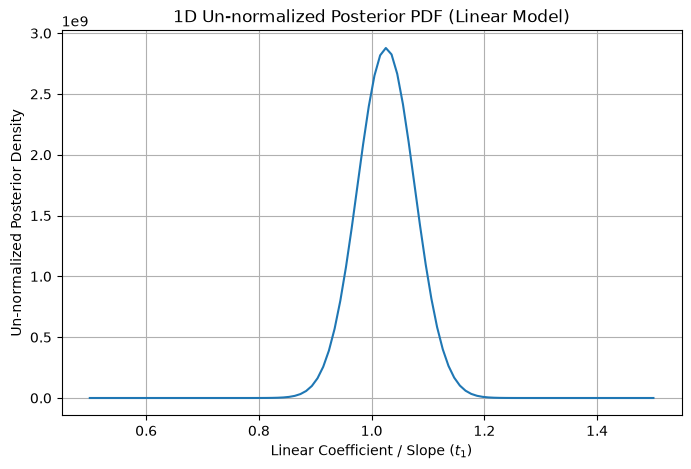

-- Pt 3 --
Bayesian Evidence (Linear Model): 3.6568e+08



In [ ]:
### Part 1 ###
data = np.load("C:/Users/aaron/Git/repos/astrostats_ttu_fall26/coursework/student_folders/aaron_hawley/homeworks/hw_data/hw4_data_2.npy")
x, y, sigma_y = data
intercept = -0.23

print("-- Pt. 1 --")
print(f"Data arrays successfully assigned. Dimensions: {data.shape}\n")

### Part 2 ###
slope_grid = np.linspace(0.5, 1.5, 100)
prior_linear = 1.0 / (1.5 - 0.5)

unnorm_post_linear = np.zeros_like(slope_grid)
for i, slope in enumerate(slope_grid):
    theta = [intercept, slope]
    unnorm_post_linear[i] = np.exp(logL(theta, data)) * prior_linear

plt.figure(figsize=(8, 5))
plt.plot(slope_grid, unnorm_post_linear)
plt.title(r'1D Un-normalized Posterior PDF (Linear Model)')
plt.xlabel(r'Linear Coefficient / Slope ($t_1$)')
plt.ylabel(r'Un-normalized Posterior Density')
plt.grid(True)
plt.show()

### Part 3 ###
evidence_linear = trapezoid(unnorm_post_linear, slope_grid)

print("-- Pt 3 --")
print(f"Bayesian Evidence (Linear Model): {evidence_linear:.4e}\n")

### Part 4 ###
linear_grid = np.linspace(0.5, 1.5, 100)
quad_grid = np.linspace(-1.0, 0.25, 100)
prior_quad_model = (1.0 / (1.5 - 0.5)) * (1.0 / (0.25 - (-1.0)))

unnorm_post_quad = np.zeros((len(quad_grid), len(linear_grid)))

for i, q in enumerate(quad_grid):
    for j, l in enumerate(linear_grid):
        theta = [intercept, l, q]
        unnorm_post_quad[i, j] = np.exp(logL(theta, data)) * prior_quad_model

plt.figue(figsize=(8,6))
plt.imshow(
    unnorm_post_quad,
    origin='lower',
    aspect='auto',
    extent=[linear_grid[0], linear_grid[-1], quad_grid[0], quad_grid[-1]],
    cmap='viridis'
)
plt.colorbar(label='Un-normalized Posterior Density')
plt.title(r'2D Joint Un-normalized Posterior PDF (Quadratic Model)')
plt.xlabel(r'Linear Coefficient ($t_1$)')
plt.ylabel(r'Quadratic Coefficient ($t_2$)')
plt.show()

### Part 5 ###
evidence_quad = trapezoid(trapezoid(unnorm_post_quad, linear_grid, axis=1), quad_grid)

print("-- Pt. 5 --")
print(f"Bayesian Evidence (Quadratic Model): {evidence_quad:.4e}\n")

### Part 6 ###
bayes_factor = evidence_linear / evidence_quad

print("-- Pt. 6 --")
print(f"Bayes Factor (Linear / Quadratic): {bayes_factor:.4f}\n")

print("BIC vs. Bayes Factor Comparison Context:")
print("1. The Bayes Factor integrates over the explicit prior parameter spaces.")
print(" This means it penalizes complex models based on custom prior widths.")
print("2. The BIC uses a generic sample size approximation: k * ln(N).")
print(" BIC completely ignores the actual geometry and boundary size of your priors.")